# 11 · Sentiment Analysis on Social Media Text (Module III)

**Theory.** Sentiment analysis classifies text as negative, neutral or positive. Tweets are harder
than news: they are short, informal, full of @mentions, hashtags, emoji, slang and elongations
("sooo good"), and sarcasm flips meaning. Preprocessing must turn these into useful tokens instead of
deleting them (nb01 `clean(mode="tweet")`). Word vectors should come from the same *domain*:
`glove-twitter-100` was trained on 2B tweets, so it has vectors for "lol", "ur" and "omg" that
Wikipedia vectors lack. **TweetEval's official metric is macro-recall**: the average recall of the
three classes, which is robust to class imbalance.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import src.utils  # FIRST: cache folders

import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
import gensim.downloader as api
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from src.utils import FAST, SEED, get_device
from src.data import TWEET_LABELS, load
from src.preprocess import clean
from src.evaluate import classification_metrics, plot_confusion, save_results

transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)
print("FAST mode:", FAST)

/Users/mihirmandavia/nlp-news/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FAST mode: False


## Data: TweetEval sentiment (official train / test split)

In [2]:
train, test = load("tweet_train"), load("tweet_test")
dist = pd.DataFrame({"train": train.label_name.value_counts(normalize=True),
                     "test": test.label_name.value_counts(normalize=True)}).loc[TWEET_LABELS].round(3)
print(f"train {len(train):,} tweets, test {len(test):,} tweets")
dist

train 45,615 tweets, test 12,284 tweets


,train,test
label_name,,
negative,0.155,0.323
neutral,0.453,0.483
positive,0.391,0.193


**Label shift:** negative tweets are twice as common in test as in train, and positive ones half as
common. A model that learns the training prior will under-predict "negative". Accuracy would reward
ignoring the minority class; macro-recall does not.

In [3]:
EMOJI = re.compile("[\U0001F000-\U0001FAFF☀-➿]")
has_emoji = test.text.map(lambda t: bool(EMOJI.search(t))).to_numpy()
print(f"tweets containing emoji: train {train.text.map(lambda t: bool(EMOJI.search(t))).mean():.1%}, "
      f"test {has_emoji.mean():.1%} ({has_emoji.sum():,} tweets)")

tweets containing emoji: train 0.0%, test 6.6% (814 tweets)


Train has **no emoji at all** (the older SemEval training data had them stripped), while ~6.6% of test
tweets have them. Any emoji-specific feature is unseen in training. The only way emoji can help is by
mapping them to words the model *has* seen ("😂" → "laugh", "😍" → "love").

## Preprocessing: with and without emoji/hashtag handling (the ablation)

In [4]:
variants = {"full": dict(handle_emoji=True, handle_hashtags=True),
            "no emoji handling": dict(handle_emoji=False, handle_hashtags=True),
            "no hashtag handling": dict(handle_emoji=True, handle_hashtags=False),
            "neither": dict(handle_emoji=False, handle_hashtags=False)}
cleaned = {}
t = time.perf_counter()
for v, kw in variants.items():
    for split, df in [("train", train), ("test", test)]:
        cleaned[(v, split, "lemma")] = [clean(x, mode="tweet", **kw) for x in df.text]
        cleaned[(v, split, "raw")] = [clean(x, mode="tweet", lemma=False, **kw).split() for x in df.text]
print(f"cleaned {len(cleaned)} variants in {time.perf_counter() - t:.0f}s")
ex = test[has_emoji].head(4).index
pd.DataFrame({"tweet": test.text[ex].values,
              "full": [cleaned[("full", "test", "lemma")][i] for i in ex],
              "neither": [cleaned[("neither", "test", "lemma")][i] for i in ex]})

cleaned 16 variants in 111s


,tweet,full,neither
0,How many more days until opening day? 😩,many day open day tire,many day open day
1,#onedirection #harrystyles cute little dance 😉,onedirection harrystyles cute little dance,onedirection harrystyles cute little dance
2,@user ohhh ok i see 🤔 what if u have medical marijuana clearance? Does that make a difference,user ohh ok see think u medical marijuana clearance make difference,user ohh ok see u medical marijuana clearance make difference
3,The United Nations Headquarters in New York #unitednations #newyork #usa🇺🇸 #USA #newyorkcity…,united nation headquarter new york unitednations newyork usa usa newyorkcity…,united nation headquarter new york unitednations newyork usa usa newyorkcity…


## Model 1: TF-IDF (uni+bigram) + logistic regression

In [5]:
def evaluate(pred):
    m = classification_metrics(test.label, pred, TWEET_LABELS)
    m_emoji = classification_metrics(test.label[has_emoji], pred[has_emoji], TWEET_LABELS)
    return m, m_emoji

runs = {}
for v in variants:
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, tokenizer=str.split, lowercase=False, token_pattern=None)
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    t = time.perf_counter()
    clf.fit(vec.fit_transform(cleaned[(v, "train", "lemma")]), train.label)
    fit_s = time.perf_counter() - t
    pred = clf.predict(vec.transform(cleaned[(v, "test", "lemma")]))
    runs[("TF-IDF + LR", v)] = (pred, fit_s, *evaluate(pred))

## Model 2: GloVe-Twitter averaged vectors + logistic regression

In [6]:
t = time.perf_counter()
glove_tw = api.load("glove-twitter-100")
print(f"glove-twitter-100: {len(glove_tw):,} words, loaded in {time.perf_counter() - t:.0f}s")

def mean_vectors(token_lists, kv):
    X = np.zeros((len(token_lists), kv.vector_size), dtype=np.float32)
    oov = total = 0
    for i, toks in enumerate(token_lists):
        known = [w for w in toks if w in kv.key_to_index]
        oov += len(toks) - len(known); total += len(toks)
        if known:
            X[i] = kv[known].mean(axis=0)
    return X, oov / max(total, 1)

oov_rates = {}
for v in variants:
    Xtr, _ = mean_vectors(cleaned[(v, "train", "raw")], glove_tw)
    Xte, oov_rates[v] = mean_vectors(cleaned[(v, "test", "raw")], glove_tw)
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    t = time.perf_counter(); clf.fit(Xtr, train.label); fit_s = time.perf_counter() - t
    pred = clf.predict(Xte)
    runs[("GloVe-Twitter avg + LR", v)] = (pred, fit_s, *evaluate(pred))
print("GloVe-Twitter test OOV rate:", {k: f"{v:.1%}" for k, v in oov_rates.items()})

glove-twitter-100: 1,193,514 words, loaded in 58s


GloVe-Twitter test OOV rate: {'full': '7.7%', 'no emoji handling': '7.7%', 'no hashtag handling': '9.3%', 'neither': '9.4%'}


## Reference ceiling: twitter-roberta-base-sentiment-latest
⚠️ **Not a fair comparison.** This RoBERTa was pre-trained on ~124M tweets and fine-tuned for
sentiment by the TweetEval authors' group (Cardiff NLP), very likely on data overlapping this
benchmark. It is shown only as an upper reference point. It reads raw tweets (its own tokenizer).

In [7]:
device = get_device()
rb_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"
rb_tok = AutoTokenizer.from_pretrained(rb_name)
rb = AutoModelForSequenceClassification.from_pretrained(rb_name).to(device).eval()
assert [rb.config.id2label[i] for i in range(3)] == TWEET_LABELS   # same label order as TweetEval

texts = test.text.tolist()
if FAST:
    texts = texts[:500]
preds = []
t = time.perf_counter()
with torch.no_grad():
    for i in range(0, len(texts), 64):
        enc = rb_tok(texts[i:i + 64], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        preds.append(rb(**enc).logits.argmax(-1).cpu())
rb_ms = (time.perf_counter() - t) / len(texts) * 1000
rb_pred = torch.cat(preds).numpy()
if FAST:  # pad so shapes match; FAST results are not reported
    rb_pred = np.concatenate([rb_pred, np.ones(len(test) - len(rb_pred), dtype=int)])
runs[("twitter-RoBERTa (reference, not fair)", "raw text")] = (rb_pred, 0.0, *evaluate(rb_pred))
print(f"RoBERTa inference {rb_ms:.1f} ms/tweet on {device}")

RoBERTa inference 14.8 ms/tweet on mps


## Results

In [8]:
rows = []
for (model, v), (pred, fit_s, m, m_emo) in runs.items():
    rows.append({"model": model, "preprocessing": v, "macro-recall": m["macro_recall"],
                 "macro-F1": m["macro_f1"], "accuracy": m["accuracy"],
                 "negative recall": m["per_class"]["negative"]["recall"],
                 "macro-F1 (emoji tweets)": m_emo["macro_f1"], "fit s": round(fit_s, 1)})
table = pd.DataFrame(rows).set_index(["model", "preprocessing"])
table

macro-recall  \
model                                 preprocessing                       
TF-IDF + LR                           full                       0.5743   
                                      no emoji handling          0.5681   
                                      no hashtag handling        0.5701   
                                      neither                    0.5646   
GloVe-Twitter avg + LR                full                       0.6082   
                                      no emoji handling          0.6052   
                                      no hashtag handling        0.6101   
                                      neither                    0.6073   
twitter-RoBERTa (reference, not fair) raw text                   0.7349   

                                                           macro-F1  accuracy  \
model                                 preprocessing                             
TF-IDF + LR                           full                   0.5712    0.5969   
                                      no emoji handling      0.5657    0.5930   
                                      no hashtag handling    0.5685    0.5957   
                                      neither                0.5638    0.5931   
GloVe-Twitter avg + LR                full                   0.6046    0.6114   
                                      no emoji handling      0.6032    0.6114   
                                      no hashtag handling    0.6061    0.6124   
                                      neither                0.6048    0.6121   
twitter-RoBERTa (reference, not fair) raw text               0.7240    0.7218   

                                                           negative recall  \
model                                 preprocessing                          
TF-IDF + LR                           full                          0.3829   
                                      no emoji handling             0.3766   
                                      no hashtag handling           0.3797   
                                      neither                       0.3719   
GloVe-Twitter avg + LR                full                          0.5637   
                                      no emoji handling             0.5604   
                                      no hashtag handling           0.5723   
                                      neither                       0.5690   
twitter-RoBERTa (reference, not fair) raw text                      0.8066   

                                                           macro-F1 (emoji tweets)  \
model                                 preprocessing                                  
TF-IDF + LR                           full                                  0.5772   
                                      no emoji handling                     0.5754   
                                      no hashtag handling                   0.5746   
                                      neither                               0.5684   
GloVe-Twitter avg + LR                full                                  0.6198   
                                      no emoji handling                     0.6271   
                                      no hashtag handling                   0.6103   
                                      neither                               0.6244   
twitter-RoBERTa (reference, not fair) raw text                              0.7224   

                                                           fit s  
model                                 preprocessing               
TF-IDF + LR                           full                   2.3  
                                      no emoji handling      2.9  
                                      no hashtag handling    3.0  
                                      neither                3.3  
GloVe-Twitter avg + LR                full                   0.8  
                                      no emoji handling      0.9  

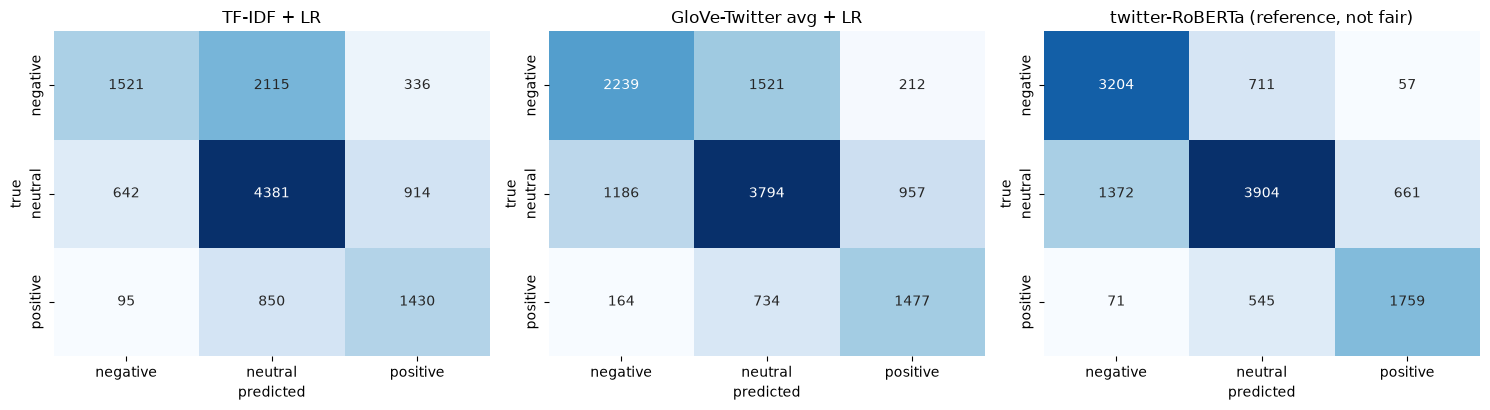

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, key in zip(axes, [("TF-IDF + LR", "full"), ("GloVe-Twitter avg + LR", "full"),
                          ("twitter-RoBERTa (reference, not fair)", "raw text")]):
    plot_confusion(test.label, runs[key][0], TWEET_LABELS, ax=ax, title=key[0])
plt.tight_layout(); plt.show()

### Ablation: does emoji/hashtag handling help?
Paired bootstrap on the test set (1,000 resamples) for the macro-F1 difference "full − variant",
on all tweets, on emoji tweets and on hashtag tweets. Switching off one step at a time shows which
step causes any gain.

In [10]:
rng = np.random.default_rng(SEED)
from sklearn.metrics import f1_score
def boot_diff(pa, pb, mask, n=1000):
    y, pa, pb = test.label.to_numpy()[mask], pa[mask], pb[mask]
    diffs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        diffs.append(f1_score(y[idx], pa[idx], average="macro") - f1_score(y[idx], pb[idx], average="macro"))
    return f1_score(y, pa, average="macro") - f1_score(y, pb, average="macro"), np.percentile(diffs, [2.5, 97.5])

from src.preprocess import _EMOTICON
has_hashtag = test.text.str.contains(r"#\w", regex=True).to_numpy()
has_emoticon = test.text.map(lambda t: bool(_EMOTICON.search(t))).to_numpy()   # :) :( :D ;) :P
print(f"test tweets with emoji {has_emoji.mean():.1%}, emoticons {has_emoticon.mean():.1%}, "
      f"hashtags {has_hashtag.mean():.1%} | train tweets with emoticons "
      f"{train.text.map(lambda t: bool(_EMOTICON.search(t))).mean():.1%}")
ablation = []
for model in ["TF-IDF + LR", "GloVe-Twitter avg + LR"]:
    for off, subset, mask in [("neither", "all tweets", np.ones(len(test), bool)),
                              ("no emoji handling", "all tweets", np.ones(len(test), bool)),
                              ("no emoji handling", f"emoji tweets (n={has_emoji.sum()})", has_emoji),
                              ("no emoji handling", f"emoticon tweets (n={has_emoticon.sum()})", has_emoticon),
                              ("no emoji handling", f"tweets with neither (n={(~has_emoji & ~has_emoticon).sum()})",
                               ~has_emoji & ~has_emoticon),
                              ("no hashtag handling", "all tweets", np.ones(len(test), bool)),
                              ("no hashtag handling", f"hashtag tweets (n={has_hashtag.sum()})", has_hashtag)]:
        d, (lo, hi) = boot_diff(runs[(model, "full")][0], runs[(model, off)][0], mask)
        ablation.append({"model": model, "full vs": off, "subset": subset, "macro-F1 gain of full": round(d, 4),
                         "95% CI": f"[{lo:+.4f}, {hi:+.4f}]", "significant": bool(lo > 0 or hi < 0)})
abl = pd.DataFrame(ablation)
# Where does TF-IDF's emoji-handling gain come from? Test tweets WITHOUT emoji/emoticons cannot be
# affected at prediction time, so a gain there must come from what the model learned in training.
row = abl[(abl.model == "TF-IDF + LR") & abl.subset.str.startswith("tweets with neither")].iloc[0]
print("TF-IDF gain on tweets with no emoji/emoticon:", row["macro-F1 gain of full"], row["95% CI"],
      "-> training-side effect" if row.significant else "-> not significant")
abl

test tweets with emoji 6.6%, emoticons 0.4%, hashtags 39.3% | train tweets with emoticons 3.1%


TF-IDF gain on tweets with no emoji/emoticon: 0.0032 [+0.0007, +0.0054] -> training-side effect


,model,full vs,subset,macro-F1 gain of full,95% CI,significant
0,TF-IDF + LR,neither,all tweets,0.0074,"[+0.0027, +0.0120]",True
1,TF-IDF + LR,no emoji handling,all tweets,0.0056,"[+0.0025, +0.0086]",True
2,TF-IDF + LR,no emoji handling,emoji tweets (n=814),0.0018,"[-0.0265, +0.0308]",False
3,TF-IDF + LR,no emoji handling,emoticon tweets (n=44),0.0101,"[-0.2038, +0.2159]",False
4,TF-IDF + LR,no emoji handling,tweets with neither (n=11426),0.0032,"[+0.0007, +0.0054]",True
5,TF-IDF + LR,no hashtag handling,all tweets,0.0027,"[-0.0013, +0.0063]",False
6,TF-IDF + LR,no hashtag handling,hashtag tweets (n=4823),0.0041,"[-0.0047, +0.0127]",False
7,GloVe-Twitter avg + LR,neither,all tweets,-0.0002,"[-0.0044, +0.0039]",False
8,GloVe-Twitter avg + LR,no emoji handling,all tweets,0.0013,"[-0.0012, +0.0038]",False
9,GloVe-Twitter avg + LR,no emoji handling,emoji tweets (n=814),-0.0072,"[-0.0317, +0.0148]",False


**Reading the ablation** (conclusions below were checked against the table; re-check if data changes):
- For TF-IDF, the "emoji handling" step gives a small but significant gain on *all* tweets, but **no
  measurable gain on the emoji tweets** (814) or the emoticon tweets (only 44 in test). The printed
  check above looks at tweets containing *neither*. A gain there cannot come from prediction-time
  preprocessing, so it must come from **training**: 3.1% of training tweets contain emoticons, which
  the same step turns into "happy"/"sad"/"laugh", changing the weights learned for those words.
  The size of this effect (well under 1 point) is the honest answer to "does emoji handling help?".
- Hashtag splitting shows no significant effect: only CamelCase tags split ("#ThankYouObama"), while
  most are lower-case ("#onedirection" stays one token).
- For GloVe-Twitter, nothing is significant. Averaging dilutes a single "happy" or "love" token
  among the tweet's other words.

**Why GloVe-Twitter beats TF-IDF here, unlike on news (nb02 vs nb05):** tweets are short, so sparse
features see few words per tweet, while pre-trained vectors carry knowledge of words that are rare in
the 45k training tweets. Its negative-class recall is also much higher, which matters under this label
shift. TF-IDF + LR mostly learns the training prior (few negatives).

In [11]:
save_results("tweet_sentiment", {
    "dataset": "tweet_eval/sentiment", "n_train": len(train), "n_test": len(test),
    "label_distribution": dist.to_dict(), "test_emoji_share": round(float(has_emoji.mean()), 4),
    "results": table.reset_index().to_dict("records"), "ablation": ablation,
    "glove_twitter_test_oov": {k: round(v, 4) for k, v in oov_rates.items()},
    "roberta_ms_per_tweet": round(rb_ms, 2), "roberta_note": "reference ceiling, not a fair comparison",
})

saved results/tweet_sentiment.json


PosixPath('/Users/mihirmandavia/nlp-news/results/tweet_sentiment.json')

## Viva notes
**Q1. Why macro-recall / macro-F1 instead of accuracy?**
Classes are imbalanced and the test distribution differs from train (negatives are 15.5% of train
but 32.3% of test). Macro averaging gives each class equal weight, so a model cannot score well by
ignoring the negative class.

**Q2. Why use glove-twitter instead of glove-wiki for tweets?**
Domain match: Twitter vectors were learned from how words are used in tweets, so slang, abbreviations
and informal spellings have vectors (lower OOV rate), and neighbours reflect social-media usage.

**Q3. Why is the RoBERTa comparison unfair?**
It was pre-trained on tweets and fine-tuned for sentiment by the same group that built TweetEval,
possibly on overlapping data. Our models learn only from TweetEval's training split. It shows a
ceiling, not a fair head-to-head result.